# Projeto LusoEnergia — Parte I: Carregamento, Auditoria e Exploração Estatística

Este notebook reúne todo o fluxo de trabalho da **Parte I**:
1. **Configuração da Janela Temporal (18 meses)** personalizada para o grupo.
2. **Carregamento, Tipagem e Validação (`1.1`)** diretamente a partir do ficheiro `.zip`.
3. **Auditoria de Qualidade e Missing Values (`1.2`)** com identificação de falhas pontuais e dias inteiros em falta.
4. **Remoção de Outliers e Análise Estatística (`1.3`)**: filtragem prévia de anomalias seguida do sumário estatístico e da tabela dinâmica horária/semanal.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

## 0. Configuração da Janela Temporal do Grupo

Defina a variável `SOMA_DOS_NUMEROS_DE_ALUNO` com a soma exata dos números de aluno dos elementos do grupo.

In [2]:
# Substituir pela soma exata dos números de aluno do vosso grupo
SOMA_DOS_NUMEROS_DE_ALUNO = 101833

rng = np.random.default_rng(SOMA_DOS_NUMEROS_DE_ALUNO)
inicio = pd.Timestamp(rng.choice(pd.date_range('2007-01-01', '2009-05-01', freq='MS')))
fim = inicio + pd.DateOffset(months=18)

print(f"Janela de análise sorteada para o grupo:")
print(f" -> Início: {inicio.strftime('%Y-%m-%d')}")
print(f" -> Fim:    {fim.strftime('%Y-%m-%d')}")

Janela de análise sorteada para o grupo:
 -> Início: 2008-08-01
 -> Fim:    2010-02-01


## 1.1 Carregamento, Tipagem e Validação dos Dados

- Leitura direta do ficheiro `.zip` (`compression='zip'`).
- Conversão de `?` para `NaN` e tipagem em `float32` para otimização de memória.
- Criação do índice temporal contínuo (`DatetimeIndex`) e validação via `assert`.

In [3]:
def carregar_dados(caminho_zip, inicio=None, fim=None):
    dtypes = {
        'Date': 'str',
        'Time': 'str',
        'Global_active_power': 'float32',
        'Global_reactive_power': 'float32',
        'Voltage': 'float32',
        'Global_intensity': 'float32',
        'Sub_metering_1': 'float32',
        'Sub_metering_2': 'float32',
        'Sub_metering_3': 'float32'
    }
    
    print(f"A ler dados do ficheiro: {caminho_zip}...")
    df = pd.read_csv(
        caminho_zip, 
        sep=';', 
        na_values=['?'], 
        dtype=dtypes,
        low_memory=False,
        compression='zip'
    )
    
    print("A converter datas e horas...")
    df['datetime'] = pd.to_datetime(
        df['Date'] + ' ' + df['Time'], 
        format='%d/%m/%Y %H:%M:%S'
    )
    
    df.drop(columns=['Date', 'Time'], inplace=True)
    df.set_index('datetime', inplace=True)
    
    if inicio is not None and fim is not None:
        print(f"A filtrar para a janela temporal: {inicio} a {fim}...")
        df = df.loc[inicio:fim]

    # Validações de integridade obrigatórias
    assert isinstance(df.index, pd.DatetimeIndex), "O índice não é um DatetimeIndex."
    assert df.index.is_monotonic_increasing, "O índice temporal não está ordenado."
    assert df.index.is_unique, "Existem datas/horas duplicadas no índice."
    if not df['Global_active_power'].isna().all():
        assert (df['Global_active_power'].dropna() >= 0).all(), "Existem valores negativos de potência."
    assert df.shape[1] == 7, "O número de variáveis (colunas) não corresponde ao esperado."
    
    return df

In [4]:
possiveis_caminhos = [
    '../data/raw/individual+household+electric+power+consumption.zip',
    'data/raw/individual+household+electric+power+consumption.zip',
    '../data/raw/household_power_consumption.zip',
    'data/raw/household_power_consumption.zip'
]

caminho_ficheiro = next((p for p in possiveis_caminhos if os.path.exists(p)), possiveis_caminhos[0])

df = carregar_dados(caminho_ficheiro, inicio, fim)
print(f"\nSucesso! O dataset tem {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head()

A ler dados do ficheiro: ../data/raw/individual+household+electric+power+consumption.zip...
A converter datas e horas...
A filtrar para a janela temporal: 2008-08-01 00:00:00 a 2010-02-01 00:00:00...

Sucesso! O dataset tem 790561 linhas e 7 colunas.


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2008-08-01 00:00:00,0.500,0.226,239.750000,2.4,0.0,0.0,1.0
2008-08-01 00:01:00,0.482,0.224,240.339996,2.2,0.0,0.0,1.0
2008-08-01 00:02:00,0.502,0.234,241.679993,2.4,0.0,0.0,0.0
2008-08-01 00:03:00,0.556,0.228,241.750000,2.6,0.0,0.0,1.0
2008-08-01 00:04:00,0.854,0.342,241.550003,4.0,0.0,1.0,7.0


## 1.2 Auditoria de Qualidade (Missing Values)

Quantificação de valores em falta por variável, identificação de dias inteiros sem medições e visualização através de um mapa térmico diário.

Resumo de Valores Nulos por Variável:


,Total_Nulos,Percentagem_(%)
Global_active_power,7536,0.953247
Global_reactive_power,7536,0.953247
Voltage,7536,0.953247
Global_intensity,7536,0.953247
Sub_metering_1,7536,0.953247
Sub_metering_2,7536,0.953247
Sub_metering_3,7536,0.953247



Número de dias inteiros sem qualquer medição: 2
Datas sem qualquer medição:
[datetime.date(2009, 6, 14), datetime.date(2010, 1, 13)]


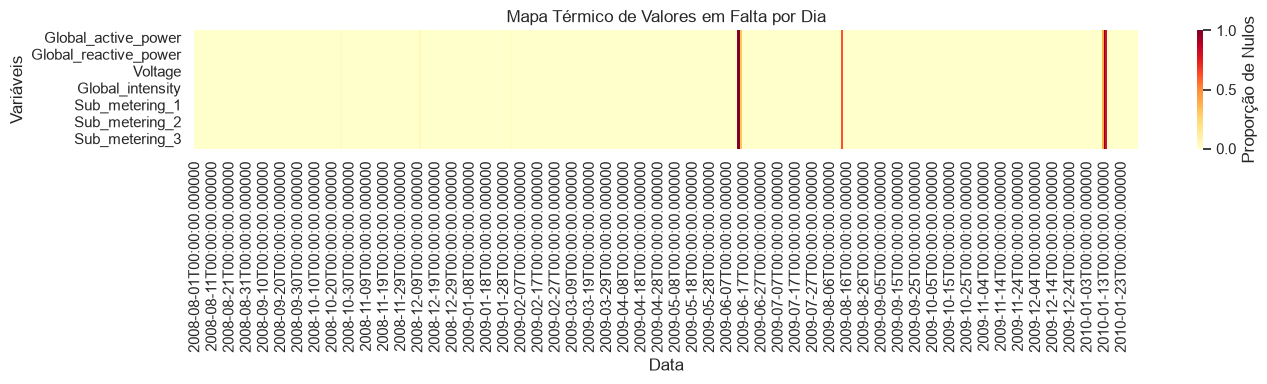

In [5]:
def analisar_missing_values(df):
    missing_abs = df.isna().sum()
    missing_pct = (df.isna().sum() / len(df)) * 100
    
    resumo_missing = pd.DataFrame({
        'Total_Nulos': missing_abs,
        'Percentagem_(%)': missing_pct
    })
    print("Resumo de Valores Nulos por Variável:")
    display(resumo_missing)
    
    leituras_diarias = df['Global_active_power'].resample('D').count()
    dias_sem_leitura = leituras_diarias[leituras_diarias == 0]
    print(f"\nNúmero de dias inteiros sem qualquer medição: {len(dias_sem_leitura)}")
    
    if len(dias_sem_leitura) > 0:
        print("Datas sem qualquer medição:")
        print(list(dias_sem_leitura.index.date))

    plt.figure(figsize=(14, 4))
    heatmap_data = df.resample('D').apply(lambda x: x.isna().mean()).T
    sns.heatmap(heatmap_data, cmap="YlOrRd", cbar_kws={'label': 'Proporção de Nulos'})
    plt.title('Mapa Térmico de Valores em Falta por Dia')
    plt.xlabel('Data')
    plt.ylabel('Variáveis')
    plt.tight_layout()
    plt.show()
    
    return resumo_missing, dias_sem_leitura

resumo_missing, dias_sem_leitura = analisar_missing_values(df)

## 1.3 Remoção de Outliers e Análise Estatística

1. **Remoção Prévia de Outliers:** Filtragem dos registos extremos através da regra `1.5 x IQR` (ou `zscore`) antes do cálculo das estatísticas.
2. **Sumário Estatístico (Sem Outliers):** Métricas descritivas calculadas sobre os dados já filtrados.
3. **Tabela Dinâmica (Pivot Table):** Perfil médio de consumo (sem outliers) cruzando a **Hora do Dia** com o **Dia da Semana**.

In [6]:
def remover_outliers(df, coluna='Global_active_power', metodo='iqr'):
    print(f"--- Remoção de Outliers ({coluna} | Método: {metodo.upper()}) ---")
    
    col_valida = df[coluna].dropna()
    
    if metodo == 'iqr':
        Q1 = col_valida.quantile(0.25)
        Q3 = col_valida.quantile(0.75)
        IQR = Q3 - Q1
        limite_inf = Q1 - 1.5 * IQR
        limite_sup = Q3 + 1.5 * IQR
        
        is_outlier = (df[coluna] < limite_inf) | (df[coluna] > limite_sup)
        print(f"Limites IQR definidos: [{limite_inf:.2f}, {limite_sup:.2f}]")
        
    elif metodo == 'zscore':
        mediana = col_valida.median()
        mad = stats.median_abs_deviation(col_valida)
        z_score_robusto = 0.6745 * (df[coluna] - mediana) / mad
        
        is_outlier = np.abs(z_score_robusto) > 3
        print("Critério aplicado: |Z-Score Robusto| > 3")
    else:
        raise ValueError("Método inválido. Escolha 'iqr' ou 'zscore'.")

    # Remove apenas os registos sinalizados como outliers (mantendo eventuais NaNs intactos)
    df_limpo = df[~is_outlier].copy()
    
    n_removidos = is_outlier.sum()
    pct_removidos = (n_removidos / len(col_valida)) * 100
    print(f"Outliers removidos: {n_removidos} linhas ({pct_removidos:.2f}% dos dados válidos)")
    print(f"Registos restantes para análise: {len(df_limpo)} linhas")
    
    return df_limpo

# 1. Remover outliers antes da análise estatística (altere metodo='zscore' se preferir Z-Score Robusto)
df_sem_outliers = remover_outliers(df, coluna='Global_active_power', metodo='iqr')

--- Remoção de Outliers (Global_active_power | Método: IQR) ---
Limites IQR definidos: [-1.51, 3.35]
Outliers removidos: 32447 linhas (4.14% dos dados válidos)
Registos restantes para análise: 758114 linhas


In [7]:
def gerar_sumario(df):
    print("--- Sumário Estatístico (Sem Outliers) ---")
    sumario = df.describe()
    display(sumario)
    return sumario

# 2. Sumário estatístico calculado sobre o DataFrame sem outliers
sumario = gerar_sumario(df_sem_outliers)

--- Sumário Estatístico (Sem Outliers) ---


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,750578.000000,750578.000000,750578.000000,750578.00000,750578.000000,750578.000000,750578.000000
mean,0.937521,0.121501,241.866791,3.95812,0.328307,0.649292,6.257695
std,0.776090,0.109545,2.882835,3.21773,3.016684,2.937380,8.359326
min,0.076000,0.000000,223.990005,0.20000,0.000000,0.000000,0.000000
25%,0.306000,0.048000,240.059998,1.40000,0.000000,0.000000,0.000000
50%,0.530000,0.100000,241.779999,2.40000,0.000000,0.000000,1.000000
75%,1.464000,0.190000,243.580002,6.00000,0.000000,1.000000,18.000000
max,3.344000,1.240000,254.149994,16.40000,52.000000,52.000000,31.000000


--- Tabela Dinâmica: Consumo Médio Sem Outliers (Global_active_power) ---


Dia_Semana,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Hora,,,,,,,
0,0.500,0.508,0.514,0.434,0.518,0.502,0.957
1,0.433,0.420,0.448,0.398,0.466,0.481,0.719
2,0.400,0.425,0.442,0.409,0.420,0.455,0.583
3,0.454,0.422,0.412,0.368,0.419,0.477,0.496
4,0.494,0.412,0.433,0.430,0.418,0.476,0.424
5,0.440,0.422,0.466,0.445,0.430,0.516,0.463
6,0.745,0.733,0.795,0.778,0.792,0.616,0.454
7,1.671,1.682,1.697,1.575,1.535,1.391,0.537
8,1.344,1.572,1.419,1.444,1.418,1.427,0.826


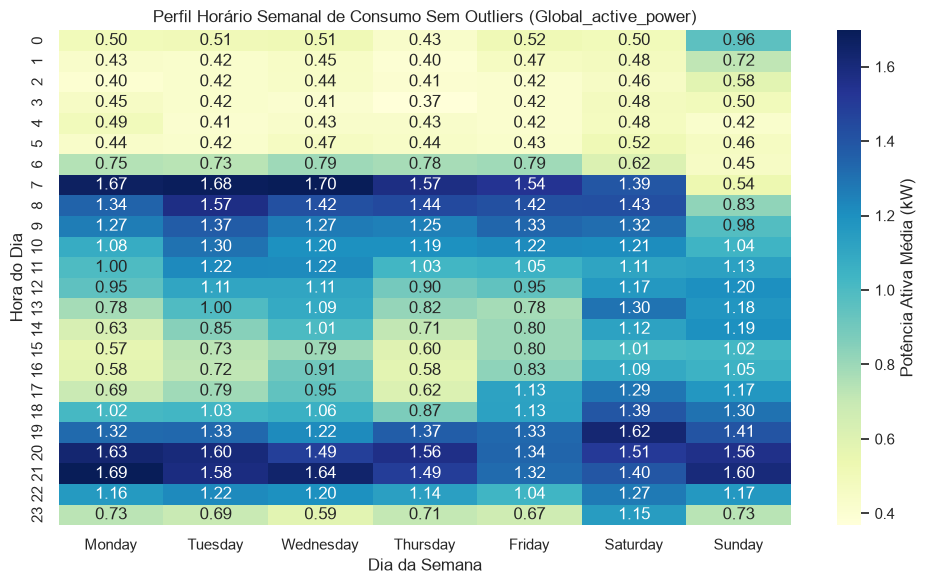

In [8]:
def gerar_tabela_dinamica(df, coluna='Global_active_power'):
    print(f"--- Tabela Dinâmica: Consumo Médio Sem Outliers ({coluna}) ---")
    
    df_temp = df.copy()
    df_temp['Hora'] = df_temp.index.hour
    df_temp['Dia_Semana'] = df_temp.index.day_name()
    
    pivot = pd.pivot_table(
        df_temp, 
        values=coluna, 
        index='Hora', 
        columns='Dia_Semana', 
        aggfunc='mean'
    )
    
    dias_ordem = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
    pivot = pivot.reindex(columns=dias_ordem)
    
    display(pivot.round(3))
    
    plt.figure(figsize=(10, 6))
    sns.heatmap(pivot, cmap="YlGnBu", annot=True, fmt=".2f", cbar_kws={'label': 'Potência Ativa Média (kW)'})
    plt.title(f'Perfil Horário Semanal de Consumo Sem Outliers ({coluna})')
    plt.xlabel('Dia da Semana')
    plt.ylabel('Hora do Dia')
    plt.tight_layout()
    plt.show()
    
    return pivot

# 3. Tabela dinâmica calculada sobre o DataFrame sem outliers
pivot_consumo = gerar_tabela_dinamica(df_sem_outliers, coluna='Global_active_power')